# Phân loại chuyên mục từ tiêu đề VietnamNet

**CO5177 · Text · Nhóm CTG**  
Huỳnh Thành Đạt (2570161) và Lương Minh Duy (2570083).

So sánh TF-IDF từ, TF-IDF ký tự và đặc trưng PhoBERT đóng băng để phân loại 19 chuyên mục từ tiêu đề. Notebook audit corpus, chọn cohort 400 tiêu đề mỗi lớp, chia train/validation/test, fit các bộ phân loại và lưu kết quả mới cho mỗi lần chạy.

## 1. Môi trường và hồ sơ lần chạy

Trong Colab sạch, notebook lấy mã nguồn và cài các phụ thuộc nghiên cứu. Dữ liệu thô và trọng số được tải theo checksum hoặc revision đã khóa. Mỗi lần chạy tạo thư mục mới dưới `artifacts/notebook-runs/text/`, chứa cấu hình, seed, lịch sử chọn tham số, chỉ số, dự đoán, biểu đồ và mô hình đã fit. Notebook không đọc kết quả test hay classifier đã lưu từ lần chạy trước.

In [1]:
from pathlib import Path
import os, sys, subprocess, importlib.util

# Từ Colab: clone mã nguồn nếu notebook không nằm trong checkout.
if Path.cwd().name == 'notebooks':
    os.chdir(Path.cwd().parent)
if not Path('configs/tabular.json').exists():
    checkout = Path('/content/CO5177-PFDAV')
    if not checkout.exists():
        subprocess.run(['git', 'clone', '--depth', '1', 'https://github.com/dathuynh1108/CO5177-PFDAV.git', str(checkout)], check=True)
    os.chdir(checkout)

REPO = Path.cwd().resolve()
required = ['numpy', 'pandas', 'sklearn', 'pyarrow', 'matplotlib', 'torch', 'transformers', 'pyvi']
missing = [name for name in required if importlib.util.find_spec(name) is None]
if missing:
    subprocess.run([sys.executable, '-m', 'pip', 'install', '-r', 'requirements-studies.txt'], check=True)
sys.path.insert(0, str(REPO / 'src'))
import json, hashlib, time, platform, joblib
from datetime import datetime, timezone
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.model_selection import train_test_split
from sklearn.metrics import ConfusionMatrixDisplay
from studies.evidence import metrics, sha256

with open(REPO / 'configs/text.json', encoding='utf-8') as f:
    config = json.load(f)
RUN_ID = datetime.now(timezone.utc).strftime('%Y%m%dT%H%M%SZ')
OUTPUT_ROOT = REPO / 'artifacts' / 'notebook-runs' / 'text' / RUN_ID
OUTPUT_ROOT.mkdir(parents=True, exist_ok=False)
(OUTPUT_ROOT / 'config.json').write_text(json.dumps(config, ensure_ascii=False, indent=2) + '\n')
print(f"Run ID: {RUN_ID} | seed: {config['model_seed']} | split seed: {config['split_seed']}")
print(f"Kết quả lần chạy này: {OUTPUT_ROOT}")

Run ID: 20261106T192012Z | seed: 42 | split seed: 2026
Kết quả lần chạy này: /Users/huynhthanhdat/Workspace/research/CO5177-PFDAV/artifacts/notebook-runs/text/20261106T192012Z


## 2. Nguồn dữ liệu và khảo sát cohort

Đọc 19 tệp parquet gốc, kiểm tra schema/checksum, làm sạch tiêu đề và gộp các nhóm trùng theo URL hoặc tiêu đề chuẩn hóa. Nhóm có chuyên mục mâu thuẫn bị loại trước khi lấy tối đa 400 mẫu mỗi lớp. Huấn luyện chỉ dùng tiêu đề; nội dung bài, URL và nhãn không đi vào đặc trưng.

Corpus nguồn: 212,705; tiêu đề rỗng: 1,167; nhóm mâu thuẫn: 3,628; bài sau làm sạch: 207,614; cohort: 7,600


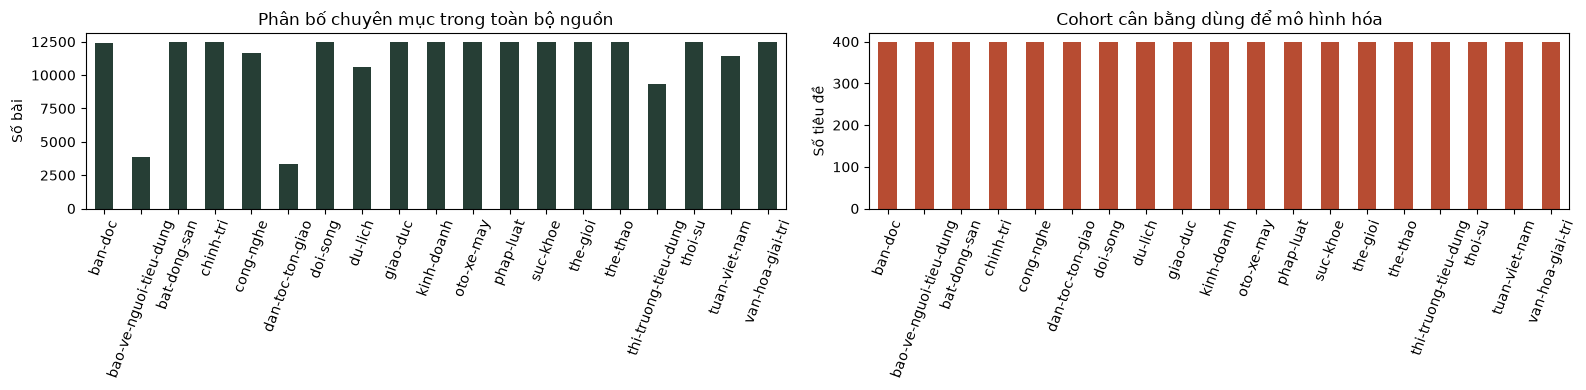

In [2]:
from studies.text import prepare, segmented_headlines, embeddings
from sklearn.dummy import DummyClassifier
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.svm import LinearSVC

frame, data_audit = prepare(config)
print(f"Corpus nguồn: {data_audit['raw_rows']:,}; tiêu đề rỗng: {data_audit['empty_headlines_removed']:,}; "
      f"nhóm mâu thuẫn: {data_audit['conflicting_category_rows_removed']:,}; "
      f"bài sau làm sạch: {data_audit['unique_usable_rows']:,}; cohort: {len(frame):,}")
class_counts = frame['category'].value_counts().sort_index()
source_counts = pd.Series(data_audit['raw_class_counts']).sort_index()
fig, axes = plt.subplots(1, 2, figsize=(16, 4))
source_counts.plot.bar(ax=axes[0], color='#263e35', rot=70)
axes[0].set(title='Phân bố chuyên mục trong toàn bộ nguồn', ylabel='Số bài')
class_counts.reindex(source_counts.index).plot.bar(ax=axes[1], color='#b74c32', rot=70)
axes[1].set(title='Cohort cân bằng dùng để mô hình hóa', ylabel='Số tiêu đề')
fig.tight_layout(); fig.savefig(OUTPUT_ROOT / 'class_counts.png', dpi=160)
plt.show(); plt.close(fig)
data_audit['selected_class_counts'] = {str(k): int(v) for k, v in class_counts.items()}
(OUTPUT_ROOT / 'data_audit.json').write_text(json.dumps(data_audit, ensure_ascii=False, indent=2) + '\n')

texts = np.asarray(segmented_headlines(frame), dtype=object)
labels = sorted(frame['category'].unique())
label_ids = {label: index for index, label in enumerate(labels)}
target = frame['category'].map(label_ids).to_numpy()

## 3. Chia tập, biểu diễn và huấn luyện

Split phân tầng 5.320/1.140/1.140 dùng seed 2026 và 2027. Từ vựng và IDF được fit trên train. PhoBERT phiên bản cố định ở chế độ eval và không cập nhật trọng số; notebook trích xuất biểu diễn mean pooling có mask. Cache embedding chỉ được dùng khi khóa hash khớp đúng văn bản, revision mô hình, cấu hình pooling và mã trích xuất; nếu không có cache hợp lệ, embedding được tính lại từ mô hình đã khóa. Các bộ phân loại vẫn được fit trong notebook.

In [3]:
train_idx, remainder_idx = train_test_split(np.arange(len(frame)), test_size=0.30,
    random_state=config['split_seed'], stratify=target)
validation_idx, test_idx = train_test_split(remainder_idx, test_size=0.5,
    random_state=config['split_seed'] + 1, stratify=target[remainder_idx])
print('Train / validation / test:', len(train_idx), len(validation_idx), len(test_idx))

# Cache embedding được dùng khi hash khớp; nếu cache miss, hàm tính lại từ model revision khóa.
cache_keys_before = {p.name for p in (REPO / 'data/text-features').glob('*') if p.is_dir()}
phobert_features, encoding_info = embeddings(texts.tolist(), config)
cache_reused = encoding_info['feature_cache_key'] in cache_keys_before
run_encoding_info = {**encoding_info, 'verified_embedding_cache_reused': cache_reused}
print('PhoBERT:', {k: encoding_info[k] for k in ['model', 'revision', 'device', 'rows', 'max_length', 'pooling', 'encoding_seconds']})
print('Dùng lại embedding cache đã kiểm checksum:', cache_reused)
(OUTPUT_ROOT / 'phobert_features.json').write_text(json.dumps(run_encoding_info, ensure_ascii=False, indent=2) + '\n')

records, models, fit_history = [], {}, []
for name, kind, c_values in [
    ('Majority baseline', 'majority', [None]),
    ('Word TF-IDF + Linear SVM', 'word', config['classifier_c']),
    ('Character TF-IDF + Linear SVM', 'character', config['classifier_c']),
    ('Frozen PhoBERT + Logistic regression', 'phobert', config['classifier_c']),
]:
    best_score, best_model, best_c = -1.0, None, None
    trials = []
    for c in c_values:
        if kind == 'majority':
            model = DummyClassifier(strategy='most_frequent')
            train_features = np.ones((len(train_idx), 1))
            validation_features = np.ones((len(validation_idx), 1))
        elif kind == 'phobert':
            model = LogisticRegression(C=c, max_iter=2000, random_state=config['model_seed'])
            train_features, validation_features = phobert_features[train_idx], phobert_features[validation_idx]
        else:
            vectorizer = TfidfVectorizer(
                analyzer='word' if kind == 'word' else 'char_wb',
                ngram_range=(1, 2) if kind == 'word' else (3, 5),
                min_df=2, max_df=0.98, max_features=config['max_features'], sublinear_tf=True)
            classifier = LinearSVC(C=c, dual='auto', max_iter=5000, random_state=config['model_seed'])
            model = Pipeline([('tfidf', vectorizer), ('classifier', classifier)])
            train_features, validation_features = texts[train_idx], texts[validation_idx]
        started = time.perf_counter()
        model.fit(train_features, target[train_idx])
        elapsed = time.perf_counter() - started
        validation_prediction = model.predict(validation_features)
        score = metrics(target[validation_idx], validation_prediction, labels)
        trial = {'C': c, 'validation_accuracy': score['accuracy'],
                 'validation_macro_f1': score['macro_f1'], 'fit_seconds': elapsed}
        trials.append(trial); fit_history.append({'model': name, **trial})
        print(f"{name} C={c}: validation macro-F1={score['macro_f1']:.4f}; fit={elapsed:.2f}s")
        if score['macro_f1'] > best_score:
            best_score, best_model, best_c = score['macro_f1'], model, c
    models[name] = best_model
    records.append({'name': name, 'kind': kind, 'selected_C': best_c,
                    'validation_macro_f1': best_score, 'validation_trials': trials})

(OUTPUT_ROOT / 'fit_history.json').write_text(json.dumps(fit_history, ensure_ascii=False, indent=2) + '\n')
(OUTPUT_ROOT / 'splits.json').write_text(json.dumps({
    'train_ids': frame.iloc[train_idx]['id'].tolist(),
    'validation_ids': frame.iloc[validation_idx]['id'].tolist(),
    'test_ids': frame.iloc[test_idx]['id'].tolist()}, ensure_ascii=False) + '\n')

Train / validation / test: 5320 1140 1140


PhoBERT: {'model': 'vinai/phobert-base-v2', 'revision': '86cd7fd4c148980922ac11a2cf5e257f2ba639e1', 'device': 'mps', 'rows': 7600, 'max_length': 128, 'pooling': 'Attention-mask mean including BOS/EOS', 'encoding_seconds': 19.190076958038844}
Dùng lại embedding cache đã kiểm checksum: True
Majority baseline C=None: validation macro-F1=0.0053; fit=0.00s
Word TF-IDF + Linear SVM C=0.5: validation macro-F1=0.6326; fit=0.15s


Word TF-IDF + Linear SVM C=1.0: validation macro-F1=0.6223; fit=0.16s
Word TF-IDF + Linear SVM C=2.0: validation macro-F1=0.6107; fit=0.17s


Character TF-IDF + Linear SVM C=0.5: validation macro-F1=0.6435; fit=0.55s


Character TF-IDF + Linear SVM C=1.0: validation macro-F1=0.6368; fit=0.63s


Character TF-IDF + Linear SVM C=2.0: validation macro-F1=0.6267; fit=0.70s


Frozen PhoBERT + Logistic regression C=0.5: validation macro-F1=0.7625; fit=0.66s


Frozen PhoBERT + Logistic regression C=1.0: validation macro-F1=0.7576; fit=0.70s


Frozen PhoBERT + Logistic regression C=2.0: validation macro-F1=0.7488; fit=0.62s


516850

## 4. Đánh giá trên test

Sau khi chọn $C$ bằng validation, dùng cùng test 1.140 tiêu đề cho mọi mô hình. Lưu dự đoán từng mẫu, chỉ số tổng hợp, ma trận nhầm lẫn, mô hình đã fit và các lỗi tiêu đề để khảo sát.

In [4]:
test_target = target[test_idx]
predictions = pd.DataFrame({'id': frame.iloc[test_idx]['id'].to_numpy(), 'target': test_target})
for record in records:
    name, kind = record['name'], record['kind']
    if kind == 'majority':
        test_features = np.ones((len(test_idx), 1))
    elif kind == 'phobert':
        test_features = phobert_features[test_idx]
    else:
        test_features = texts[test_idx]
    predicted = models[name].predict(test_features)
    measured = metrics(test_target, predicted, labels)
    record['test'] = measured
    predictions[name] = predicted
    joblib.dump(models[name], OUTPUT_ROOT / (kind + '.joblib'), compress=3)
predictions.to_csv(OUTPUT_ROOT / 'predictions.csv', index=False)
summary = {'track': 'text', 'run_id': RUN_ID, 'seed': config['model_seed'],
           'split_seed': config['split_seed'], 'split_sizes': {
               'train': len(train_idx), 'validation': len(validation_idx), 'test': len(test_idx)},
           'classes': labels, 'models': records, 'pretrained': run_encoding_info}
(OUTPUT_ROOT / 'metrics.json').write_text(json.dumps(summary, ensure_ascii=False, indent=2) + '\n')
rows = [{'Mô hình': r['name'], 'C': r['selected_C'],
         'Validation macro-F1': r['validation_macro_f1'],
         'Test accuracy': r['test']['accuracy'], 'Test macro-F1': r['test']['macro_f1']}
        for r in records]
display(pd.DataFrame(rows).set_index('Mô hình').round(4))
chosen = max(records, key=lambda r: r['validation_macro_f1'])
errors = frame.iloc[test_idx][['id', 'url', 'category']].copy()
errors['prediction'] = [labels[i] for i in predictions[chosen['name']]]
errors.loc[errors['category'] != errors['prediction']].head(30).to_csv(OUTPUT_ROOT / 'errors.csv', index=False)

,C,Validation macro-F1,Test accuracy,Test macro-F1
Mô hình,,,,
Majority baseline,NaN,0.0053,0.0526,0.0053
Word TF-IDF + Linear SVM,0.5,0.6326,0.6632,0.6582
Character TF-IDF + Linear SVM,0.5,0.6435,0.6728,0.6676
Frozen PhoBERT + Logistic regression,0.5,0.7625,0.7754,0.7738


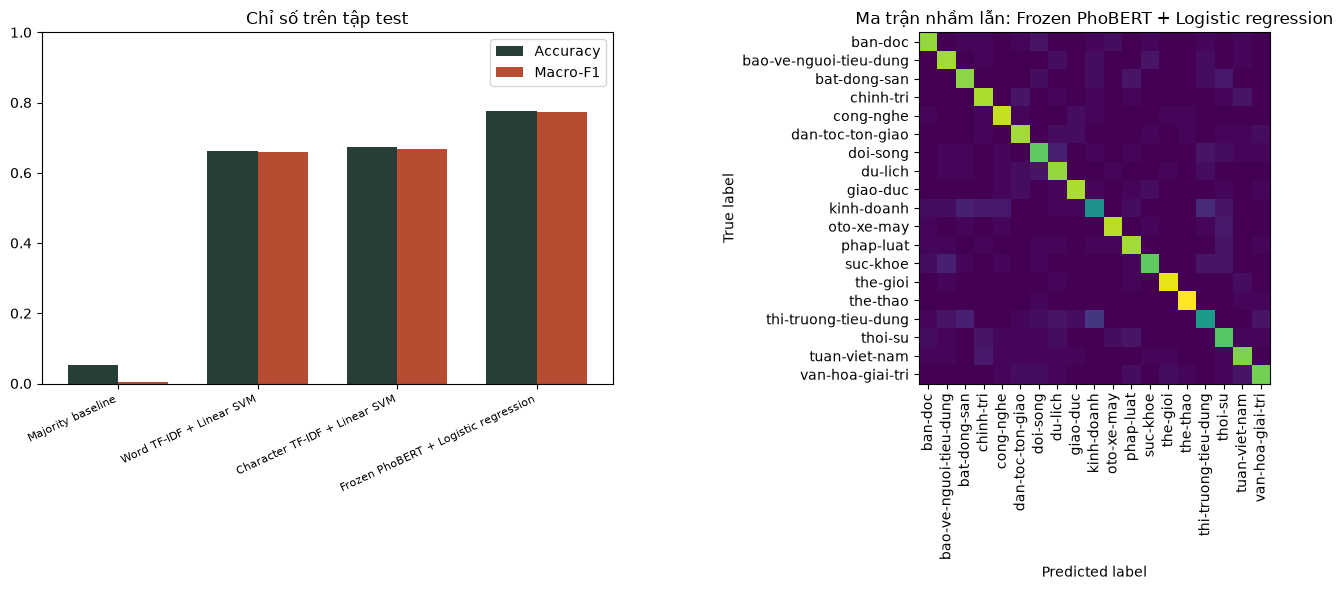

,Chuyên mục,F1,Precision,Recall
9,kinh-doanh,0.537,0.604,0.483
15,thi-truong-tieu-dung,0.554,0.596,0.517
16,thoi-su,0.667,0.636,0.700
6,doi-song,0.717,0.717,0.717
7,du-lich,0.744,0.696,0.800
17,tuan-viet-nam,0.767,0.767,0.767
12,suc-khoe,0.768,0.827,0.717
2,bat-dong-san,0.770,0.758,0.783


Đã lưu dự đoán, mô hình, cấu hình, lịch sử fit, chỉ số, lỗi và biểu đồ tại /Users/huynhthanhdat/Workspace/research/CO5177-PFDAV/artifacts/notebook-runs/text/20261106T192012Z


In [5]:
fig, axes = plt.subplots(1, 2, figsize=(14, 6))
model_names = [r['name'] for r in records]; x = np.arange(len(model_names))
axes[0].bar(x - 0.18, [r['test']['accuracy'] for r in records], 0.36, label='Accuracy', color='#263e35')
axes[0].bar(x + 0.18, [r['test']['macro_f1'] for r in records], 0.36, label='Macro-F1', color='#b74c32')
axes[0].set_xticks(x, model_names, rotation=25, ha='right', fontsize=8)
axes[0].set_ylim(0, 1); axes[0].set_title('Chỉ số trên tập test'); axes[0].legend()
ConfusionMatrixDisplay(np.asarray(chosen['test']['confusion']), display_labels=labels).plot(
    ax=axes[1], colorbar=False, include_values=False, xticks_rotation=90)
axes[1].set_title('Ma trận nhầm lẫn: ' + chosen['name'])
fig.tight_layout(); fig.savefig(OUTPUT_ROOT / 'test_metrics_confusion.png', dpi=160)
plt.show(); plt.close(fig)
per_class = chosen['test']['per_class']
display(pd.DataFrame([{'Chuyên mục': label, 'F1': per_class[label]['f1-score'],
                      'Precision': per_class[label]['precision'], 'Recall': per_class[label]['recall']}
                     for label in labels]).sort_values('F1').head(8).round(3))
print('Đã lưu dự đoán, mô hình, cấu hình, lịch sử fit, chỉ số, lỗi và biểu đồ tại', OUTPUT_ROOT)

## 5. Nhận xét và giới hạn

PhoBERT đóng băng kết hợp hồi quy logistic đạt accuracy 77,54% và macro-F1 0,7738; TF-IDF ký tự đạt lần lượt 67,28% và 0,6676. So sánh phản ánh toàn bộ pipeline trên cohort cân bằng, không cô lập riêng tác động của encoder và classifier. Kết quả chỉ áp dụng cho tiêu đề, một split và 400 tiêu đề mỗi lớp; không đại diện phân bố chuyên mục triển khai hoặc phân loại toàn văn. Nội dung bài báo không được phát hành lại trong Git.

## 6. Khai báo sử dụng AI

Phạm vi hỗ trợ của AI được trình bày trong [AI_USE_REPORT.md](https://github.com/dathuynh1108/CO5177-PFDAV/blob/main/AI_USE_REPORT.md).